# Assignment 2: Developing an End-to-End Machine Learning System
**COMSATS University Islamabad, Lahore Campus**  
**Course:** Machine Learning Fundamentals (AIC354) · **Semester:** Fall 2026  
**Tasks:** Titanic Passenger Survival Prediction and Heart Disease Prediction

> **Deployment link:** Add your own live deployment URL here after publishing the app.  
> This notebook is designed to run in Jupyter Notebook/JupyterLab. Run cells from top to bottom.

## 1. Objectives and workflow
This notebook follows the assignment's end-to-end workflow:
1. Load/collect structured data.
2. Inspect and understand the data.
3. Clean data, handle missing values, and encode categorical labels.
4. Train and evaluate a classification model.
5. Save the fitted pipeline and demonstrate predictions.
6. Prepare a small web application for cloud deployment.

**Reproducibility note:** dataset downloads require internet access the first time. The Heart Disease task intentionally uses only four input attributes, as required by the assignment. Model metrics are generated by running the notebook and depend on the data version and train/test split.

In [1]:
# If needed in a fresh environment, uncomment and run:
# %pip install pandas numpy scikit-learn matplotlib seaborn joblib ucimlrepo

import os, warnings, json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix, ConfusionMatrixDisplay,
    roc_auc_score
)

warnings.filterwarnings("ignore")
RANDOM_STATE = 42
ARTIFACTS = Path("artifacts")
ARTIFACTS.mkdir(exist_ok=True)
print("Libraries loaded. Artifacts directory:", ARTIFACTS.resolve())

Libraries loaded. Artifacts directory: C:\Users\Tehreem\Downloads\Assignment_2_Complete_Submission_Package\artifacts


## 2. Task 1 — Titanic Passenger Survival Prediction System

### 2.1 Data collection
We use the Titanic passenger dataset exposed by Seaborn. The target is `survived` (0 = did not survive, 1 = survived). We keep common passenger attributes and exclude identifiers/free-text fields that are not needed for this demonstration.

In [2]:
try:
    titanic = sns.load_dataset("titanic")
except Exception as e:
    raise RuntimeError(
        "Could not download the Seaborn Titanic dataset. Check internet access, "
        "or place a local titanic.csv in the working directory and load it with pd.read_csv."
    ) from e

print("Shape:", titanic.shape)
display(titanic.head())
display(titanic.info())
display(titanic.isna().sum().sort_values(ascending=False).to_frame("missing values"))

Shape: (891, 15)


,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype   
---  ------       --------------  -----   
 0   survived     891 non-null    int64   
 1   pclass       891 non-null    int64   
 2   sex          891 non-null    object  
 3   age          714 non-null    float64 
 4   sibsp        891 non-null    int64   
 5   parch        891 non-null    int64   
 6   fare         891 non-null    float64 
 7   embarked     889 non-null    object  
 8   class        891 non-null    category
 9   who          891 non-null    object  
 10  adult_male   891 non-null    bool    
 11  deck         203 non-null    category
 12  embark_town  889 non-null    object  
 13  alive        891 non-null    object  
 14  alone        891 non-null    bool    
dtypes: bool(2), category(2), float64(2), int64(4), object(5)
memory usage: 80.7+ KB


None

,missing values
deck,688
age,177
embarked,2
embark_town,2
sex,0
pclass,0
survived,0
fare,0
parch,0
sibsp,0


### 2.2 Data understanding and preprocessing
We select a manageable mix of numeric and categorical features. A scikit-learn pipeline imputes missing values, scales numeric features, and one-hot encodes categorical features. Using a pipeline keeps preprocessing consistent between training and future predictions and helps prevent data leakage.

In [3]:
titanic_features = ["pclass", "sex", "age", "sibsp", "parch", "fare", "embarked", "alone"]
target_titanic = "survived"
titanic_df = titanic[titanic_features + [target_titanic]].copy()
X_titanic = titanic_df[titanic_features]
y_titanic = titanic_df[target_titanic].astype(int)

numeric_titanic = ["pclass", "age", "sibsp", "parch", "fare"]
categorical_titanic = ["sex", "embarked", "alone"]

titanic_preprocessor = ColumnTransformer([
    ("num", Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]), numeric_titanic),
    ("cat", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore"))
    ]), categorical_titanic)
])

X_t_train, X_t_test, y_t_train, y_t_test = train_test_split(
    X_titanic, y_titanic, test_size=0.2, random_state=RANDOM_STATE, stratify=y_titanic
)
titanic_model = Pipeline([
    ("preprocessor", titanic_preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=300, random_state=RANDOM_STATE, class_weight="balanced"
    ))
])
titanic_model.fit(X_t_train, y_t_train)
print("Training completed.")

Training completed.


,accuracy,precision,recall,f1_score,roc_auc
Titanic Random Forest,0.8101,0.7869,0.6957,0.7385,0.8244


                 precision    recall  f1-score   support

Did not survive       0.82      0.88      0.85       110
       Survived       0.79      0.70      0.74        69

       accuracy                           0.81       179
      macro avg       0.80      0.79      0.79       179
   weighted avg       0.81      0.81      0.81       179



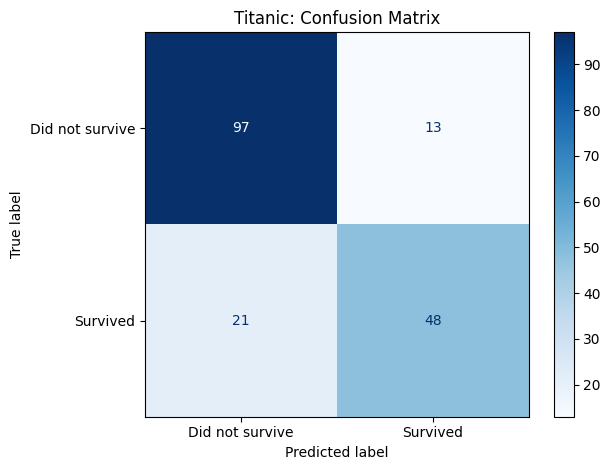

In [4]:
titanic_pred = titanic_model.predict(X_t_test)
titanic_prob = titanic_model.predict_proba(X_t_test)[:, 1]

titanic_metrics = {
    "accuracy": accuracy_score(y_t_test, titanic_pred),
    "precision": precision_score(y_t_test, titanic_pred, zero_division=0),
    "recall": recall_score(y_t_test, titanic_pred, zero_division=0),
    "f1_score": f1_score(y_t_test, titanic_pred, zero_division=0),
    "roc_auc": roc_auc_score(y_t_test, titanic_prob)
}
display(pd.DataFrame([titanic_metrics], index=["Titanic Random Forest"]).round(4))
print(classification_report(y_t_test, titanic_pred, target_names=["Did not survive", "Survived"], zero_division=0))
ConfusionMatrixDisplay.from_predictions(
    y_t_test, titanic_pred, display_labels=["Did not survive", "Survived"], cmap="Blues"
)
plt.title("Titanic: Confusion Matrix")
plt.tight_layout()
plt.show()

In [5]:
# Example prediction for a hypothetical passenger (not a real person).
titanic_example = pd.DataFrame([{
    "pclass": 3, "sex": "female", "age": 28, "sibsp": 0,
    "parch": 0, "fare": 12.0, "embarked": "S", "alone": True
}])
titanic_prediction = int(titanic_model.predict(titanic_example)[0])
titanic_probability = float(titanic_model.predict_proba(titanic_example)[0, 1])
print("Predicted class:", "Survived" if titanic_prediction else "Did not survive")
print(f"Estimated survival probability: {titanic_probability:.1%}")
joblib.dump(titanic_model, ARTIFACTS / "titanic_model.joblib")
print("Saved:", ARTIFACTS / "titanic_model.joblib")

Predicted class: Survived
Estimated survival probability: 70.7%
Saved: artifacts\titanic_model.joblib


## 3. Task 2 — Heart Disease Prediction System

### 3.1 Data collection
The assignment specifies the UCI Heart Disease dataset. The code first tries the official `ucimlrepo` package. If it is not installed or the dataset cannot be retrieved, it falls back to the processed Cleveland dataset CSV from the UCI repository. In the commonly used processed Cleveland data, `num` values greater than zero indicate the presence of heart disease; we convert this to a binary target.

**Four input attributes used (assignment constraint):** `age`, `sex`, `cp` (chest-pain type), and `thalach` (maximum heart rate achieved). This is a teaching model, not a medical diagnostic tool.

In [6]:
heart = None
heart_source = None

try:
    from ucimlrepo import fetch_ucirepo
    heart_data = fetch_ucirepo(id=45)
    heart = pd.concat([heart_data.data.features, heart_data.data.targets], axis=1)
    heart_source = "UCI ML Repository via ucimlrepo"
except Exception as e:
    fallback_url = "https://archive.ics.uci.edu/ml/machine-learning-databases/heart-disease/processed.cleveland.data"
    columns = ["age","sex","cp","trestbps","chol","fbs","restecg","thalach",
               "exang","oldpeak","slope","ca","thal","num"]
    try:
        heart = pd.read_csv(fallback_url, header=None, names=columns, na_values="?")
        heart_source = "UCI processed Cleveland CSV fallback"
    except Exception as e2:
        raise RuntimeError(
            "Could not retrieve the UCI Heart Disease data. Install ucimlrepo or "
            "download the UCI Cleveland processed data and load it locally."
        ) from e2

heart.columns = [str(c).strip().lower().replace(" ", "_") for c in heart.columns]
print("Data source:", heart_source)
print("Shape:", heart.shape)
display(heart.head())
display(heart.isna().sum().sort_values(ascending=False).to_frame("missing values"))

Data source: UCI processed Cleveland CSV fallback
Shape: (303, 14)


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,num
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,2
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,0


,missing values
ca,4
thal,2
cp,0
trestbps,0
age,0
sex,0
fbs,0
chol,0
restecg,0
thalach,0


### 3.2 Select four attributes and prepare target
UCI versions can name the target either `num` or `num`-equivalent (often `num`, or `diagnosis`). The cell below normalizes common target names and converts the outcome to binary: 0 = no disease, 1 = disease present.

In [7]:
# Normalize common names from the two supported dataset formats.
rename_map = {
    "target": "num", "diagnosis": "num", "heart_disease": "num",
    "thalachh": "thalach", "chest_pain_type": "cp"
}
heart = heart.rename(columns={k:v for k,v in rename_map.items() if k in heart.columns and v not in heart.columns})

if "num" not in heart.columns:
    possible = [c for c in heart.columns if c in ("target", "diagnosis", "heart_disease")]
    if possible:
        heart = heart.rename(columns={possible[0]: "num"})
if "num" not in heart.columns:
    raise ValueError(f"Could not identify the target column. Available columns: {list(heart.columns)}")

required = ["age", "sex", "cp", "thalach", "num"]
missing_cols = [c for c in required if c not in heart.columns]
if missing_cols:
    raise ValueError(f"Dataset is missing expected columns: {missing_cols}")

heart_df = heart[required].copy()
for c in required:
    heart_df[c] = pd.to_numeric(heart_df[c], errors="coerce")
heart_df = heart_df.dropna(subset=["num"])
heart_df["num"] = (heart_df["num"] > 0).astype(int)
heart_df = heart_df.dropna(subset=["age", "sex", "cp", "thalach"])

heart_features = ["age", "sex", "cp", "thalach"]
X_heart = heart_df[heart_features]
y_heart = heart_df["num"].astype(int)

print("Rows after cleaning:", len(heart_df))
print("Class counts (0=no disease, 1=disease):")
display(y_heart.value_counts().sort_index().rename_axis("class").to_frame("count"))
display(heart_df.describe().round(2))

Rows after cleaning: 303
Class counts (0=no disease, 1=disease):


,count
class,
0,164
1,139


,age,sex,cp,thalach,num
count,303.00,303.00,303.00,303.00,303.00
mean,54.44,0.68,3.16,149.61,0.46
std,9.04,0.47,0.96,22.88,0.50
min,29.00,0.00,1.00,71.00,0.00
25%,48.00,0.00,3.00,133.50,0.00
50%,56.00,1.00,3.00,153.00,0.00
75%,61.00,1.00,4.00,166.00,1.00
max,77.00,1.00,4.00,202.00,1.00


,accuracy,precision,recall,f1_score,roc_auc
Heart Disease Random Forest,0.7213,0.7037,0.6786,0.6909,0.8566


                 precision    recall  f1-score   support

     No disease       0.74      0.76      0.75        33
Disease present       0.70      0.68      0.69        28

       accuracy                           0.72        61
      macro avg       0.72      0.72      0.72        61
   weighted avg       0.72      0.72      0.72        61



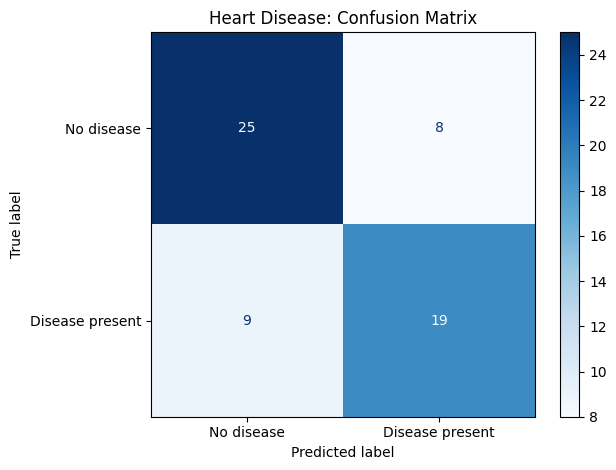

In [8]:
heart_numeric = ["age", "thalach"]
heart_categorical = ["sex", "cp"]

heart_preprocessor = ColumnTransformer([
    ("num", Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]), heart_numeric),
    ("cat", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore"))
    ]), heart_categorical)
])

X_h_train, X_h_test, y_h_train, y_h_test = train_test_split(
    X_heart, y_heart, test_size=0.2, random_state=RANDOM_STATE, stratify=y_heart
)
heart_model = Pipeline([
    ("preprocessor", heart_preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=300, random_state=RANDOM_STATE, class_weight="balanced"
    ))
])
heart_model.fit(X_h_train, y_h_train)
heart_pred = heart_model.predict(X_h_test)
heart_prob = heart_model.predict_proba(X_h_test)[:, 1]

heart_metrics = {
    "accuracy": accuracy_score(y_h_test, heart_pred),
    "precision": precision_score(y_h_test, heart_pred, zero_division=0),
    "recall": recall_score(y_h_test, heart_pred, zero_division=0),
    "f1_score": f1_score(y_h_test, heart_pred, zero_division=0),
    "roc_auc": roc_auc_score(y_h_test, heart_prob)
}
display(pd.DataFrame([heart_metrics], index=["Heart Disease Random Forest"]).round(4))
print(classification_report(y_h_test, heart_pred, target_names=["No disease", "Disease present"], zero_division=0))
ConfusionMatrixDisplay.from_predictions(
    y_h_test, heart_pred, display_labels=["No disease", "Disease present"], cmap="Blues"
)
plt.title("Heart Disease: Confusion Matrix")
plt.tight_layout()
plt.show()

In [9]:
# Example prediction using only the four permitted attributes.
heart_example = pd.DataFrame([{"age": 55, "sex": 1, "cp": 2, "thalach": 150}])
heart_prediction = int(heart_model.predict(heart_example)[0])
heart_probability = float(heart_model.predict_proba(heart_example)[0, 1])
print("Model output:", "Disease present" if heart_prediction else "No disease detected by model")
print(f"Model-estimated probability of positive class: {heart_probability:.1%}")
print("IMPORTANT: This is a classroom model and must not be used for medical decisions.")
joblib.dump(heart_model, ARTIFACTS / "heart_disease_model.joblib")
print("Saved:", ARTIFACTS / "heart_disease_model.joblib")

Model output: No disease detected by model
Model-estimated probability of positive class: 13.0%
IMPORTANT: This is a classroom model and must not be used for medical decisions.
Saved: artifacts\heart_disease_model.joblib


## 4. Compare models and summarize results
The following table compares the test-set metrics calculated above. Do not copy expected metrics from another run; use the values produced by your own notebook execution.

In [10]:
comparison = pd.DataFrame([
    {"system": "Titanic survival", **titanic_metrics},
    {"system": "Heart disease", **heart_metrics}
]).set_index("system")
display(comparison.round(4))

,accuracy,precision,recall,f1_score,roc_auc
system,,,,,
Titanic survival,0.8101,0.7869,0.6957,0.7385,0.8244
Heart disease,0.7213,0.7037,0.6786,0.6909,0.8566


## 5. Deployment preparation

The companion files in this submission package include:
- `app.py` — Streamlit interface for the two trained models.
- `requirements.txt` — Python dependencies.
- `README.md` — local run and cloud deployment instructions.

Run the notebook through the model-saving cells first so the `artifacts/` directory contains both `.joblib` model files. Then deploy `app.py` on Streamlit Community Cloud (or another supported Python hosting service). The assignment requires a live deployment URL at the top of the notebook: replace the placeholder with your actual deployed URL after deployment. I cannot create a live URL without access to your hosting account.

## 6. Conclusion
This project demonstrates two end-to-end structured-data classification workflows: data collection, exploratory inspection, preprocessing, model training, held-out evaluation, example inference, model persistence, and deployment preparation. The Titanic system predicts survival from passenger characteristics. The heart disease system uses exactly four inputs (`age`, `sex`, `cp`, `thalach`) as requested. Performance should be interpreted using multiple metrics, not accuracy alone. The heart disease model is for educational use only and is not a substitute for professional medical evaluation.